# Ridge Regularization

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import load_diabetes

data = load_diabetes()

In [3]:
print(data.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [4]:
X =data.data
Y = data.target

In [5]:
from sklearn.model_selection import train_test_split

X_train , X_test , Y_train , Y_test = train_test_split(X,Y , test_size =0.2,random_state=45)

In [6]:
from sklearn.linear_model import LinearRegression

lr =LinearRegression()

In [7]:
lr.fit(X_train,Y_train)

LinearRegression()

In [8]:
Y_pred = lr.predict(X_test)

In [13]:
from sklearn.metrics import r2_score , mean_squared_error

print("R2 score" , r2_score(Y_test , Y_pred))
print("MSE " , np.sqrt(mean_squared_error(Y_test , Y_pred)))

R2 score 0.5188113124539249
MSE  48.72713760953252


In [14]:
from sklearn.linear_model import Ridge
R = Ridge(alpha = 0.0001)


In [15]:
R.fit(X_train,Y_train)

Ridge(alpha=0.0001)

In [16]:
Y_pred = R.predict(X_test)

In [18]:
print("r2 " , r2_score(Y_test,Y_pred))
print("RMSE" , np.sqrt(mean_squared_error(Y_test,Y_pred)))

r2  0.518973263588496
RMSE 48.71893700181951


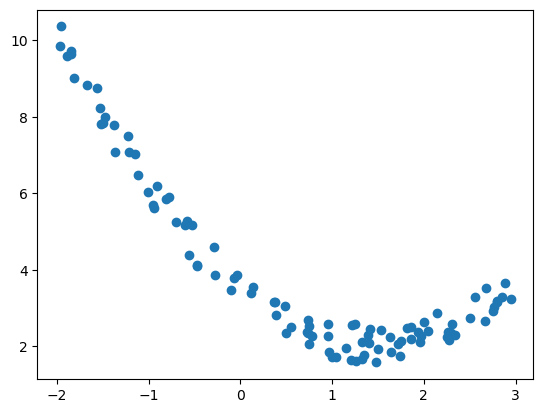

In [20]:
m =100
X1 = 5 * np.random.rand(m,1) -2
X2 = 0.7*X1**2 - 2*X1 + 3 + np.random.rand(m,1)

plt.scatter(X1,X2)
plt.show()

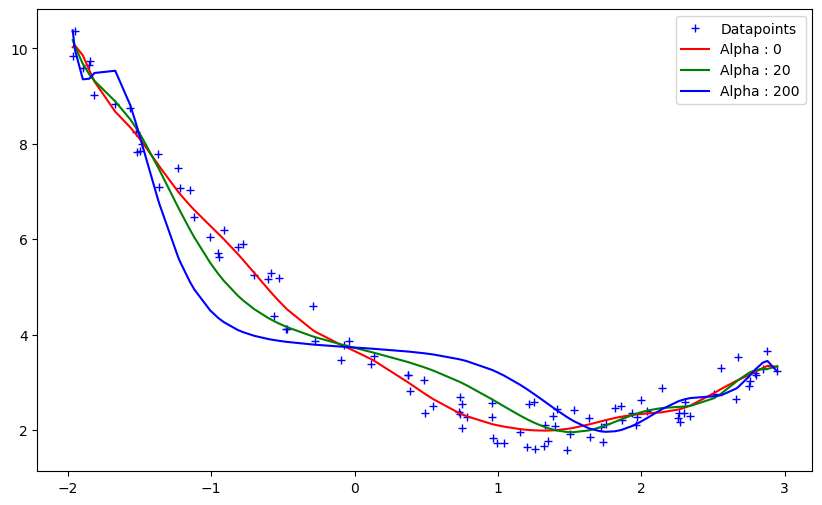

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

def get_preds_ridge(X1 , X2 ,alpha):
    model = Pipeline([
        ('poly_feats' , PolynomialFeatures(degree = 16)),
        ('ridge' , Ridge(alpha = alpha))
    ])
    model.fit(X1,X2)
    return model.predict(X1)

alphas = [0,20,200]
cs = ['r','g' ,'b']

plt.figure(figsize=(10,6))
plt.plot(X1 ,X2 , 'b+' , label = 'Datapoints')

for alpha , c in zip(alphas ,cs):
    preds = get_preds_ridge(X1,X2 ,alpha)
    #plot
    plt.plot(sorted(X1[:,0]) , preds[np.argsort(X1[:,0])] , c , label = 'Alpha : {}'.format(alpha))

plt.legend()
plt.show()    
